
# Simplified Boltzmann Machine for Product Recommendation

## Project Overview

This project demonstrates how a Restricted Boltzmann Machine (RBM)
can learn patterns from binary user-product preference data and
generate product recommendations.

## Objectives

- Prepare a user-product preference dataset.
- Initialize visible and hidden units.
- Train the model using Contrastive Divergence (CD-1).
- Evaluate reconstruction error before and after training.
- Recommend products based on estimated preference probabilities.

## Technologies Used

Python, NumPy, Pandas, Matplotlib, and Jupyter Notebook.


In [1]:

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Locate the project folder
PROJECT_ROOT = Path.cwd().parent

if not (PROJECT_ROOT / "src" / "boltzmann_machine.py").exists():
    PROJECT_ROOT = Path.cwd()

# Allow Python to import the model from src
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from boltzmann_machine import BoltzmannMachine

# Load the dataset
dataset_path = PROJECT_ROOT / "dataset" / "user_preferences.csv"
dataset = pd.read_csv(dataset_path)

# Separate user IDs from product preferences
product_names = dataset.drop(columns=["user_id"]).columns.tolist()
user_preferences = dataset[product_names].to_numpy(dtype=float)

print("Dataset loaded successfully!")
print("Number of users:", len(dataset))
print("Number of products:", len(product_names))
print("Dataset shape:", user_preferences.shape)

display(dataset)


Dataset loaded successfully!
Number of users: 8
Number of products: 5
Dataset shape: (8, 5)


,user_id,Headphones,Laptop,Smartphone,Books,Sports_Shoes
0,U1,1,1,1,0,0
1,U2,1,1,1,0,0
2,U3,1,1,0,0,0
3,U4,0,0,0,1,1
4,U5,0,0,0,1,1
5,U6,0,1,1,0,1
6,U7,1,0,1,0,0
7,U8,0,1,0,1,1


In [2]:

# Make the experiment reproducible
np.random.seed(42)

# Create the model
model = BoltzmannMachine(
    n_visible=len(product_names),
    n_hidden=3,
    learning_rate=0.1
)

print("Model initialized successfully!")
print("Visible units:", model.n_visible)
print("Hidden units:", model.n_hidden)
print("Weight matrix shape:", model.weights.shape)
print("Visible bias shape:", model.visible_bias.shape)
print("Hidden bias shape:", model.hidden_bias.shape)


Model initialized successfully!
Visible units: 5
Hidden units: 3
Weight matrix shape: (5, 3)
Visible bias shape: (5,)
Hidden bias shape: (3,)


In [3]:

initial_error = model.reconstruction_error(user_preferences)

print(
    "Initial reconstruction error:",
    round(initial_error, 4)
)


Initial reconstruction error: 0.2485


In [4]:

model.train(user_preferences, epochs=100)

final_error = model.reconstruction_error(user_preferences)

print("Training completed.")
print("Initial error:", round(initial_error, 4))
print("Final error:", round(final_error, 4))

if final_error < initial_error:
    print("Reconstruction error decreased after training.")
else:
    print("Reconstruction error did not decrease in this run.")


Training completed for 100 epochs.
Training completed.
Initial error: 0.2485
Final error: 0.2324
Reconstruction error decreased after training.


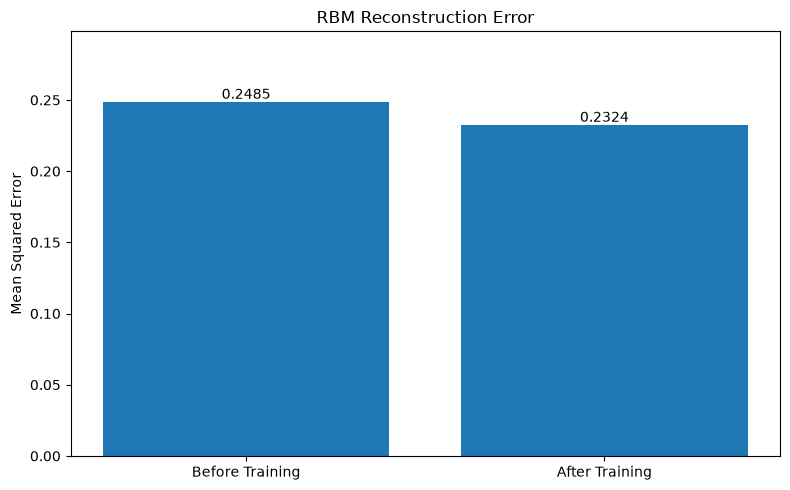

Chart saved to: c:\Projects\boltzmann-product-recommender\results\reconstruction_error.png


In [5]:

errors = [initial_error, final_error]
labels = ["Before Training", "After Training"]

plt.figure(figsize=(8, 5))
bars = plt.bar(labels, errors)

plt.title("RBM Reconstruction Error")
plt.ylabel("Mean Squared Error")
plt.ylim(0, max(errors) * 1.2)

for bar, error in zip(bars, errors):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{error:.4f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()

chart_path = PROJECT_ROOT / "results" / "reconstruction_error.png"
plt.savefig(chart_path, dpi=300)
plt.show()
plt.close()

print("Chart saved to:", chart_path)


In [6]:

# Select the first user in the dataset
user_index = 0

user_id = dataset.iloc[user_index]["user_id"]
user_vector = user_preferences[user_index]

recommendations = model.recommend(
    user_vector,
    product_names,
    top_n=3
)

print(f"Recommendations for user {user_id}:")
print()

if recommendations:
    for rank, (product, probability) in enumerate(recommendations, start=1):
        print(f"{rank}. {product}: {probability:.4f}")
else:
    print("No eligible products to recommend.")


Recommendations for user U1:

1. Sports_Shoes: 0.4519
2. Books: 0.3184


In [7]:

print("Recommendations for all users")

for index, row in dataset.iterrows():
    user_id = row["user_id"]
    preferences = user_preferences[index]

    recommendations = model.recommend(
        preferences,
        product_names,
        top_n=3
    )

    print(f"\nUser {user_id}:")

    if recommendations:
        for product, probability in recommendations:
            print(f"  {product}: {probability:.4f}")
    else:
        print("  No eligible products to recommend.")


Recommendations for all users

User U1:
  Sports_Shoes: 0.4519
  Books: 0.3184

User U2:
  Sports_Shoes: 0.4519
  Books: 0.3184

User U3:
  Smartphone: 0.5445
  Sports_Shoes: 0.4577
  Books: 0.3263

User U4:
  Laptop: 0.6019
  Smartphone: 0.5188
  Headphones: 0.4839

User U5:
  Laptop: 0.6019
  Smartphone: 0.5188
  Headphones: 0.4839

User U6:
  Headphones: 0.5003
  Books: 0.3364

User U7:
  Laptop: 0.6289
  Sports_Shoes: 0.4581
  Books: 0.3277

User U8:
  Smartphone: 0.5254
  Headphones: 0.4883



## Conclusion

The project implemented a simplified Restricted Boltzmann Machine
for product recommendation using binary user-product preferences.

The model was initialized with visible and hidden units and trained
using one-step Contrastive Divergence (CD-1).

Reconstruction error was measured before and after training and
visualized using Matplotlib. The trained model was also used to
generate ranked product recommendations for individual users.

The experiment demonstrates the basic workflow of an RBM-based
recommendation system. However, the dataset contains only eight
users and five products. The results therefore represent an
educational demonstration and do not establish recommendation
accuracy on unseen users.
